# P2.14 — Which foreign residents go with rising prices? Nationality groups

**Question:** RQ3.3 (population growth, immigration and prices) — `p2_02` used the change in *all* foreign residents; it left
nationalities unsplit. Here the same fixed-effects regression of log price-to-income, with the foreign-resident change split
into six groups: Brazil, the Portuguese-speaking African countries (Angola, Cabo Verde, Guinea-Bissau, São Tomé and Príncipe),
Eastern Europe (Romania, Moldova, Ukraine), China, the United Kingdom and all other nationalities.

Same design as `p2_02` (municipality fixed effects; year effects, or NUTS 3 × year effects; errors clustered by municipality;
2016 to 2023), same controls. Nationality is a *marker* of who arrives, not a mechanism: groups differ in where they settle,
in income and in what they buy, and a coefficient mixes all of that. Adjusted associations, not effects.

In [1]:
import pandas as pd

from pthousing.analysis import demography as dem
from pthousing.analysis import panel as pn
from pthousing.config import MUNI_KEY, YEAR_KEY
from pthousing.data import build_panel, interim
from pthousing.viz import charts, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
aima = interim.read("aima_foreigners")
frame = pn.build_frame(panel)
population = panel.set_index([MUNI_KEY, YEAR_KEY])["population_n"]
changes = dem.group_changes(aima, population)
frame = frame.join(changes)
GROUPS = list(changes.columns)
print(
    f"{len(GROUPS)} groups, {frame[GROUPS].notna().all(axis=1).sum()} municipality-years with every group"
)

6 groups, 2772 municipality-years with every group


## Step 1 — The groups
Residents with a title by group, 2014 and 2023: the groups differ in size and in growth.

In [2]:
totals = dem.nationality_totals(aima)
rows = {}
for name, codes in dem.NATIONALITY_GROUPS.items():
    s = totals[codes].sum(axis=1)
    rows[name] = {
        "residents_2014_n": s.loc[2014],
        "residents_2023_n": s.loc[2023],
        "growth_pct": 100 * (s.loc[2023] / s.loc[2014] - 1),
        "share_2023_pct": 100 * s.loc[2023] / totals["total"].loc[2023],
    }
sizes = pd.DataFrame(rows).T
style.save_table(sizes.round(1).reset_index(names="group"), "p2", "nationality_group_sizes")
sizes.round(1)

,residents_2014_n,residents_2023_n,growth_pct,share_2023_pct
brazil,85288.0,368391.0,331.9,35.3
palop,87797.0,163339.0,86.0,15.6
east_europe,77772.0,49536.0,-36.3,4.7
china,21057.0,28123.0,33.6,2.7
uk,16559.0,47407.0,186.3,4.5
other,101640.0,387442.0,281.2,37.1


## Step 2 — The regressions
Each group's change enters in the same unit (pp of last year's population), so coefficients compare directly; the chart scales
them by each group's within-municipality standard deviation, because a group that is small everywhere (China) has a large
coefficient per point and a small effect per typical change. Checks: NUTS 3 × year effects, stopping in 2022 (before the jump
in titles), and without Lisboa, Setúbal and Porto.

,spec,term,coef,se,p,coef_per_sd,n_obs,n_munis
1,Municipality + year effects,Brazil (pp of pop.),0.0788,0.0176,0.0000,0.0165,2336,298
2,Municipality + year effects,Lusophone Africa (pp of pop.),0.1051,0.0293,0.0003,0.0151,2336,298
3,Municipality + year effects,Eastern Europe (pp of pop.),0.0331,0.0554,0.5504,0.0025,2336,298
4,Municipality + year effects,China (pp of pop.),-0.1580,0.0730,0.0306,-0.0060,2336,298
5,Municipality + year effects,United Kingdom (pp of pop.),-0.0132,0.0128,0.3017,-0.0024,2336,298
6,Municipality + year effects,All other (pp of pop.),0.0225,0.0159,0.1555,0.0055,2336,298
10,Municipality + region-year effects,Brazil (pp of pop.),0.0485,0.0161,0.0026,0.0079,2336,298
11,Municipality + region-year effects,Lusophone Africa (pp of pop.),0.0540,0.0260,0.0376,0.0062,2336,298
12,Municipality + region-year effects,Eastern Europe (pp of pop.),0.0869,0.0382,0.0229,0.0060,2336,298
13,Municipality + region-year effects,China (pp of pop.),-0.1352,0.0825,0.1012,-0.0048,2336,298


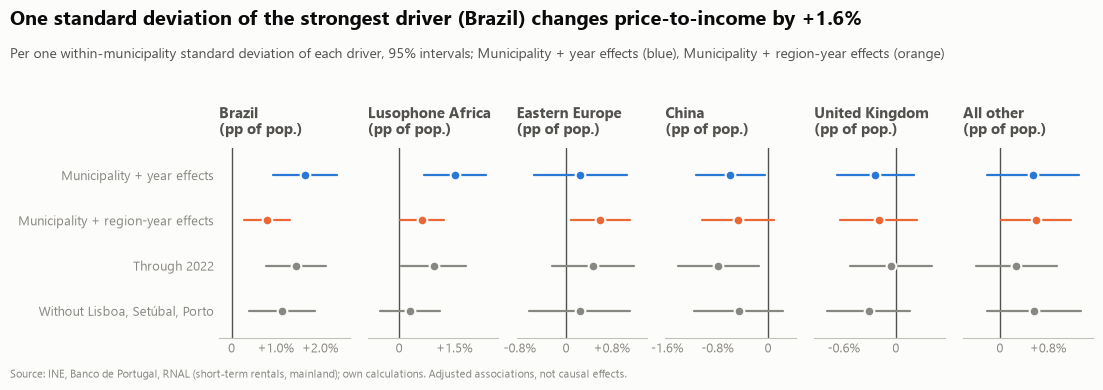

In [3]:
X = ["pop_change_ex_foreign_pct", *GROUPS, "completions_per_1000", "pop_65plus_pct"]
metro = {"exclude_district": ["Lisboa", "Setúbal", "Porto"]}
SPECS = {
    "Municipality + year effects": pn.Spec("log_pti", X),
    "Municipality + region-year effects": pn.Spec("log_pti", X, effects="region_year"),
    "Through 2022": pn.Spec("log_pti", X, years=(2016, 2022)),
    "Without Lisboa, Setúbal, Porto": pn.Spec("log_pti", X, sample=metro),
}
MAIN, COMPARE = "Municipality + year effects", "Municipality + region-year effects"
fits = {name: pn.fit(frame, spec) for name, spec in SPECS.items()}
ladder = pd.concat([pn.coef_table(res, name) for name, res in fits.items()], ignore_index=True)
style.save_table(ladder, "p2", "nationality_regressions_pti")
labels = {
    "fc_brazil_pct": "Brazil (pp of pop.)",
    "fc_palop_pct": "Lusophone Africa (pp of pop.)",
    "fc_east_europe_pct": "Eastern Europe (pp of pop.)",
    "fc_china_pct": "China (pp of pop.)",
    "fc_uk_pct": "United Kingdom (pp of pop.)",
    "fc_other_pct": "All other (pp of pop.)",
}
fig = charts.coef_ladder(ladder, labels, MAIN, COMPARE, "price-to-income", lower_label=False)
style.save_fig(fig, "p2", "nationality_coefficients_pti")
show = ladder[ladder["term"].isin(labels)].assign(term=lambda d: d["term"].map(labels))
show[["spec", "term", "coef", "se", "p", "coef_per_sd", "n_obs", "n_munis"]].round(4)

## Step 3 — Do the groups differ?
A Wald test that the six coefficients are equal, in each specification, against the single-coefficient model of `p2_02`.

In [4]:
tests = pd.DataFrame({name: pn.equal_coefficients(res, GROUPS) for name, res in fits.items()}).T
one = pn.coef_table(
    pn.fit(
        frame,
        pn.Spec(
            "log_pti",
            [
                "pop_change_ex_foreign_pct",
                "foreign_change_pct",
                "completions_per_1000",
                "pop_65plus_pct",
            ],
        ),
    ),
    "All foreign residents together",
)
style.save_table(tests.round(4).reset_index(names="spec"), "p2", "nationality_equality_tests")
print(
    one.loc[one["term"] == "foreign_change_pct", ["coef", "se", "p"]]
    .round(4)
    .to_string(index=False)
)
tests.round(4)

  coef     se   p
0.0433 0.0099 0.0


,statistic,df,p
Municipality + year effects,35.0105,5.0,0.0000
Municipality + region-year effects,13.5226,5.0,0.0189
Through 2022,27.8011,5.0,0.0000
"Without Lisboa, Setúbal, Porto",15.3673,5.0,0.0089


## Key numbers

In [5]:
for spec in (MAIN, COMPARE):
    d = ladder[(ladder["spec"] == spec) & ladder["term"].isin(labels)]
    print(spec)
    for r in d.itertuples():
        print(
            f"  {labels[r.term].split(' (')[0]}: {100 * r.coef:+.1f}% per pp [{100 * r.ci_low:+.1f}, {100 * r.ci_high:+.1f}], "
            f"{100 * r.coef_per_sd:+.2f}% per sd, p={r.p:.3f}"
        )
    t = tests.loc[spec]
    print(f"  equal coefficients: chi2({t['df']:.0f}) = {t['statistic']:.1f}, p = {t['p']:.3f}")
print(sizes.round(1).to_string())

Municipality + year effects
  Brazil: +7.9% per pp [+4.4, +11.3], +1.65% per sd, p=0.000
  Lusophone Africa: +10.5% per pp [+4.8, +16.3], +1.51% per sd, p=0.000
  Eastern Europe: +3.3% per pp [-7.6, +14.2], +0.25% per sd, p=0.550
  China: -15.8% per pp [-30.1, -1.5], -0.60% per sd, p=0.031
  United Kingdom: -1.3% per pp [-3.8, +1.2], -0.24% per sd, p=0.302
  All other: +2.3% per pp [-0.9, +5.4], +0.55% per sd, p=0.156
  equal coefficients: chi2(5) = 35.0, p = 0.000
Municipality + region-year effects
  Brazil: +4.8% per pp [+1.7, +8.0], +0.79% per sd, p=0.003
  Lusophone Africa: +5.4% per pp [+0.3, +10.5], +0.62% per sd, p=0.038
  Eastern Europe: +8.7% per pp [+1.2, +16.2], +0.60% per sd, p=0.023
  China: -13.5% per pp [-29.7, +2.6], -0.48% per sd, p=0.101
  United Kingdom: -1.5% per pp [-5.0, +1.9], -0.20% per sd, p=0.379
  All other: +2.7% per pp [+0.1, +5.4], +0.59% per sd, p=0.043
  equal coefficients: chi2(5) = 13.5, p = 0.019
             residents_2014_n  residents_2023_n  growth